# E12 — EarthCARE vs. TRMM: comparison and transfer

Both missions fly through the same simulated weather (G5NR, June 2005 – February 2006) with the same
one-minute decisions: should the radar be on this minute, judged from the passive imager and the
orbit geometry? They differ in orbit and radar:

| | EarthCARE | TRMM |
|---|---|---|
| orbit | sun-synchronous, ~97°: two local times (~01:56, ~13:56) | precessing, 35°: every local time |
| radar label | rain ≥ 1 mm/hr at **nadir** (CPR) | rain ≥ 1 mm/hr anywhere in the **247 km PR swath** |
| imager | MSI, 150 km | VIRS, 833 km |

This notebook asks four questions (docs/baseline_paper/07_experiments.md, E12):

1. **Side by side.** How do base rate, skill and budgeted capture compare?
2. **Transfer.** Does a policy trained on one mission work on the other?
3. **Local time.** Is TRMM's gate better or worse at EarthCARE's two local times than at other hours?
4. **Diurnal cycle.** How much of the day's rain falls outside EarthCARE's windows?

Every comparison uses only the latitudes both missions reach (|lat| ≤ TRMM's highest latitude), for
training and testing, so the orbit is compared and not the climate zone. The models are fitted by
`python -m baselines.compare_missions`; this notebook reads its result files.

In [1]:
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().resolve().parents[1]                 # notebook lives in missions/comparison/
assert (ROOT / "baselines" / "compare_missions.py").exists(), f"run this notebook from missions/comparison/ ({ROOT})"
RES = ROOT / "missions" / "comparison" / "results"
FIG = ROOT / "docs" / "baseline_paper" / "figures" / "comparison"
meta = json.loads((RES / "run_meta.json").read_text())
read = lambda name: pd.read_csv(RES / f"{name}.csv")
COLOR = {"EarthCARE": "#2a78d6", "TRMM": "#eb6834"}
P6, P5 = "P6 gradient boosting", "P5 logistic regression"
NODES, HW = meta["ec_windows"]["nodes_local_hour"], meta["ec_windows"]["half_width_h"]
hhmm = lambda h: f"{int(h):02d}:{round(h % 1 * 60):02d}"

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def shade_windows(ax):
    for n in NODES:
        ax.axvspan(n - HW, n + HW, color="0.9", lw=0, zorder=0)

# the datasets must be the ones E12 was run on
for name, d in meta["data"].items():
    path = ROOT / d["path"]
    report = json.loads((path.parent / "enrich_report.json").read_text())
    h = hashlib.sha256(path.read_bytes()).hexdigest()
    assert h == d["sha256"] == report["sha256"], f"{name}: dataset changed since E12 was run"
    print(f"{name:9s}: {d['path']}  sha256 {h[:12]}...  {d['rows_in_band']:,} decisions in the shared band")
print(f"shared band: |lat| <= {meta['lat_max']:.2f} deg (TRMM's highest latitude)")
print(f"EarthCARE windows: {' and '.join(hhmm(n) for n in NODES)} local time, +/- {HW:g} h")

EarthCARE: missions/earthcare/data/EarthCare_trackwise_decisions.parquet  sha256 9fe09a93c8b0...  138,424 decisions in the shared band
TRMM     : missions/trmm/data/TRMM_trackwise_decisions.parquet  sha256 fab9c8c7ebbd...  352,800 decisions in the shared band
shared band: |lat| <= 35.21 deg (TRMM's highest latitude)
EarthCARE windows: 01:56 and 13:56 local time, +/- 1 h


## 1. Side by side

Each mission's own policies (P5 logistic regression, P6 gradient boosting; Tier A inputs), trained on
June–September and tested on November–February inside the shared band. *Oracle capture@20%* is the
best any gate could do: when more than 20% of minutes are rainy, even a perfect gate cannot catch
them all. *Tier B retention* is the share of P6's capture@20% kept without optical depth (the inputs
that also work at night).

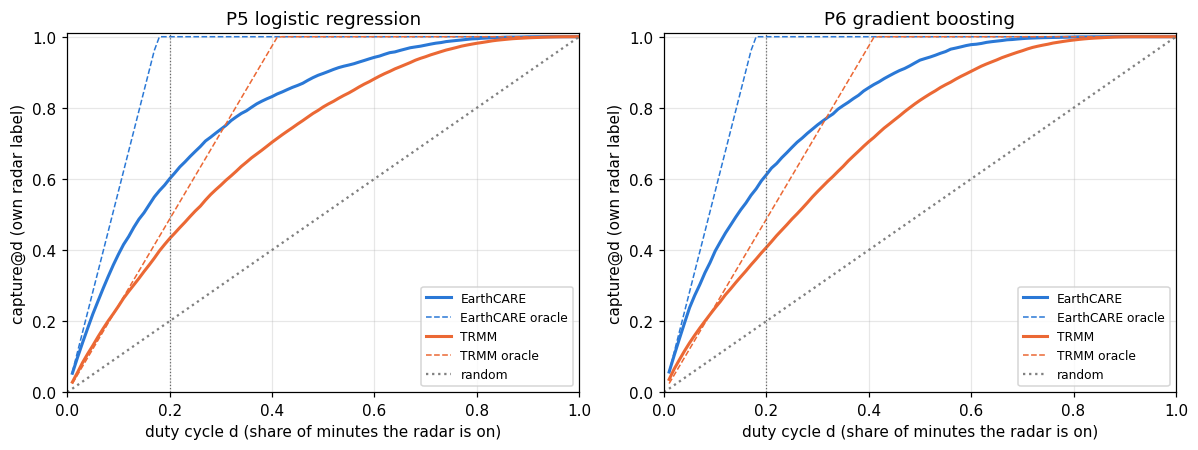


**Takeaway.** With similar imager inputs the two gates rank minutes about equally well
(P6 AUC 0.855 vs. 0.849) and lose about the same share without optical depth
(Tier B keeps 79% vs. 79%). They differ in what
the radar sees: TRMM's swath label is positive in 41% of minutes against EarthCARE's
18% at nadir, so at 20% duty TRMM's gate catches 41% of rainy minutes
out of a possible 49%, while EarthCARE's catches 61% out of
100%. TRMM is limited by its budget, EarthCARE by its skill. Scoring
against the imager swath instead of the radar inflates the positive class
2.23x for EarthCARE but only 1.54x for TRMM, whose radar
already covers a wide swath.


In [2]:
comp = read("e12_comparison")
show = comp.set_index(["mission", "policy"])[["n_test", "base_rate", "swath_rate", "swath_inflation", "auc", "ap",
                                              "capture@13%", "capture@20%", "oracle_capture@20%",
                                              "mass_capture@20%", "tier_b_retention@20%"]]
display(show.style.format({"n_test": "{:,}", "swath_inflation": "{:.2f}x", "auc": "{:.3f}", "ap": "{:.3f}",
                           **{c: "{:.1%}" for c in ["base_rate", "swath_rate", "capture@13%", "capture@20%",
                                                    "oracle_capture@20%", "mass_capture@20%",
                                                    "tier_b_retention@20%"]}}))

curves = read("e12_capture_curves")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, pol in zip(axes, (P5, P6)):
    for name, g in curves[curves.policy == pol].groupby("mission", sort=False):
        ax.plot(g["d"], g["capture"], color=COLOR[name], lw=2, label=f"{name}")
        ax.plot(g["d"], g["oracle"], "--", color=COLOR[name], lw=1, label=f"{name} oracle")
    ax.plot([0, 1], [0, 1], ":", color="0.5", label="random")
    ax.axvline(0.2, color="0.4", lw=0.8, ls=":")
    ax.set(title=pol, xlabel="duty cycle d (share of minutes the radar is on)",
           ylabel="capture@d (own radar label)", xlim=(0, 1), ylim=(0, 1.01))
    ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

e, t = (comp[(comp.mission == n) & (comp.policy == P6)].iloc[0] for n in ("EarthCARE", "TRMM"))
display(Markdown(f'''
**Takeaway.** With similar imager inputs the two gates rank minutes about equally well
(P6 AUC {e.auc:.3f} vs. {t.auc:.3f}) and lose about the same share without optical depth
(Tier B keeps {e["tier_b_retention@20%"]:.0%} vs. {t["tier_b_retention@20%"]:.0%}). They differ in what
the radar sees: TRMM's swath label is positive in {t.base_rate:.0%} of minutes against EarthCARE's
{e.base_rate:.0%} at nadir, so at 20% duty TRMM's gate catches {t["capture@20%"]:.0%} of rainy minutes
out of a possible {t["oracle_capture@20%"]:.0%}, while EarthCARE's catches {e["capture@20%"]:.0%} out of
{e["oracle_capture@20%"]:.0%}. TRMM is limited by its budget, EarthCARE by its skill. Scoring
against the imager swath instead of the radar inflates the positive class
{e.swath_inflation:.2f}x for EarthCARE but only {t.swath_inflation:.2f}x for TRMM, whose radar
already covers a wide swath.
'''))

## 2. Transfer

Train on one mission, test on the other, with only the inputs both imagers give: the shared cloud
proxies plus geometry, or geometry alone (Tier C). Two label settings:

- **nadir**: rain at nadir on both sides, so only the sampling (orbit, local time) differs;
- **own radar**: train on the source mission's own label, score the target's own label, as a gate
  carried from one mission to the other would be.

Thresholds come from the target's unlabeled validation scores: setting a duty budget needs no rain
labels. *Loss* is the target's own policy's capture@20% minus the transferred policy's, in points
(negative: the transferred policy does better).

In [3]:
tr = read("e12_transfer")
cross = tr[tr.trained_on != tr.tested_on].copy()
cross["direction"] = cross.trained_on + " -> " + cross.tested_on
loss = cross.pivot_table(index=["features", "label", "model"], columns="direction",
                         values="capture_loss_points@20%")
display(Markdown("**Capture@20% loss from transfer (points)**"))
display(loss.style.format("{:+.1f}").background_gradient(cmap="RdBu_r", vmin=-5, vmax=5))

full = tr.pivot_table(index=["features", "label", "model", "trained_on"], columns="tested_on",
                      values="capture@20%")
display(Markdown("**Capture@20%, trained on (rows) x tested on (columns)**"))
display(full.style.format("{:.1%}"))

ec_tr = cross[(cross.direction == "EarthCARE -> TRMM") & (cross.features == "shared cloud + geometry")
              & (cross.label == "nadir")].set_index("model")
worst = cross.loc[cross["capture_loss_points@20%"].idxmax()]
display(Markdown(f'''
**Takeaway.** A policy trained on EarthCARE loses
{ec_tr.loc[P6, "capture_loss_points@20%"]:.1f} points of capture@20% on TRMM with gradient boosting
({ec_tr.loc[P5, "capture_loss_points@20%"]:.1f} with logistic regression; nadir label, shared
features). The largest loss in any setting or direction is {worst["capture_loss_points@20%"]:.1f}
points ({worst.direction}, {worst.model}, {worst.label} label, {worst.features}), and
{(cross["capture_loss_points@20%"] < 0).sum()} of {len(cross)} transfers do better than the target's own
policy. Weather seen only at ~14:00 and ~02:00 is enough to rank minutes at every hour about as well
as weather from all hours. Both datasets share the same simulated weather and identically computed
features, so real sensor differences could still widen the gap.
'''))

**Capture@20% loss from transfer (points)**

**Capture@20%, trained on (rows) x tested on (columns)**


**Takeaway.** A policy trained on EarthCARE loses
1.2 points of capture@20% on TRMM with gradient boosting
(1.9 with logistic regression; nadir label, shared
features). The largest loss in any setting or direction is 2.5
points (TRMM -> EarthCARE, P5 logistic regression, own radar label, shared cloud + geometry), and
5 of 16 transfers do better than the target's own
policy. Weather seen only at ~14:00 and ~02:00 is enough to rank minutes at every hour about as well
as weather from all hours. Both datasets share the same simulated weather and identically computed
features, so real sensor differences could still widen the gap.


## 3. Local time

TRMM's own policy, scored separately inside EarthCARE's windows and at all other hours, each group
with its own validation threshold so each spends exactly 20% of its minutes. The interval comes from
resampling whole test days (minutes on one day share weather). EarthCARE's own policy, all of whose
minutes are inside the windows, is listed for comparison.

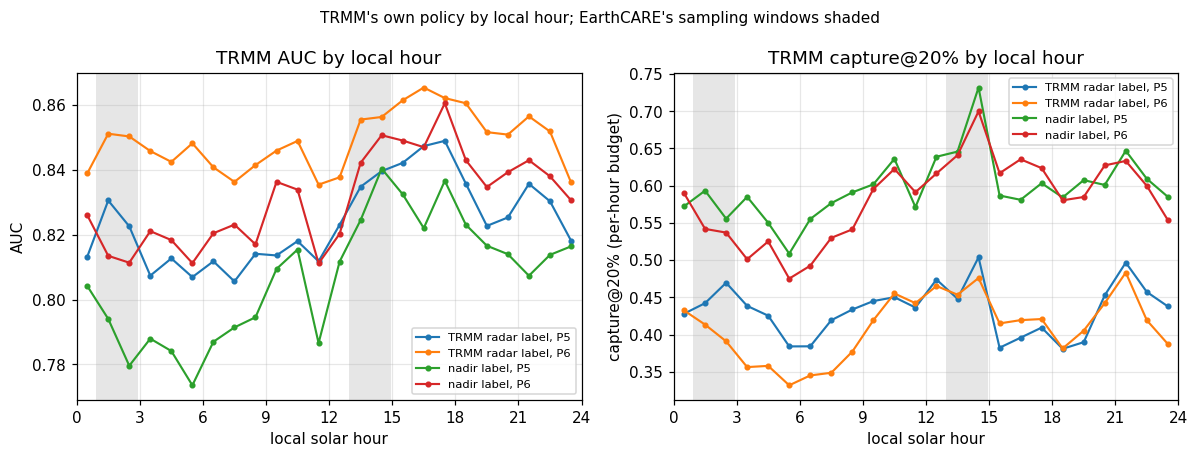


**Takeaway.** Inside EarthCARE's windows TRMM's gate catches 43.9% of rainy
minutes at 20% duty, against 40.1% at other hours (P6, radar label; gap
+3.8 points, 95% CI [+0.8, +6.8]). Across both models and
both labels the gap is +3.0 to +3.9 points, and
every interval excludes zero. Rain is
easier to find at EarthCARE's sampling times, so EarthCARE's
results slightly overstate gating skill relative to the full day.

The two windows are not alike. Averaged over their hours (P6, radar label, per-hour budget), capture@20%
is 46.5% around 13:56 and 40.2% around 01:56, against 40.5% at the
other hours: the advantage comes from the afternoon window.


In [4]:
lt = read("e12_local_time")
gap = read("e12_local_time_gap")
display(gap.set_index(["label", "model"]).style.format(
    {"capture_in_windows": "{:.1%}", "capture_other_hours": "{:.1%}", "gap_points": "{:+.1f}",
     "gap_ci_low": "{:+.1f}", "gap_ci_high": "{:+.1f}"}))
groups = lt[~lt.group.str.startswith("hour")]
display(groups.set_index(["mission", "label", "model", "group"]).style.format(
    {"n_test": "{:,}", "base_rate": "{:.1%}", "auc": "{:.3f}", "capture@20%": "{:.1%}",
     "oracle_capture@20%": "{:.1%}", "lift@20%": "{:.2f}"}))

hourly = lt[(lt.mission == "TRMM") & lt.group.str.startswith("hour")].copy()
hourly["h"] = hourly.group.str[5:].astype(int) + 0.5
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, metric, lab in ((axes[0], "auc", "AUC"), (axes[1], "capture@20%", "capture@20% (per-hour budget)")):
    shade_windows(ax)
    for (label, model), g in hourly.groupby(["label", "model"]):
        ax.plot(g["h"], g[metric], "-o", ms=3, lw=1.4, label=f"{label} label, {model.split()[0]}")
    ax.set(xlabel="local solar hour", ylabel=lab, xlim=(0, 24), xticks=range(0, 25, 3),
           title=f"TRMM {lab.split(' (')[0]} by local hour")
    ax.legend(fontsize=7.5)
fig.suptitle("TRMM's own policy by local hour; EarthCARE's sampling windows shaded", fontsize=10)
plt.tight_layout()
plt.show()

g6 = gap[(gap.label == "TRMM radar") & (gap.model == P6)].iloc[0]
excl = (gap.gap_ci_low > 0).all() or (gap.gap_ci_high < 0).all()
# the two windows separately: mean of the per-hour capture@20% over each window's hours
h6 = hourly[(hourly.label == "TRMM radar") & (hourly.model == P6)].set_index("h")["capture@20%"]
near = lambda n: np.abs((h6.index - n + 12) % 24 - 12) < HW
night, day = h6[near(NODES[0])].mean(), h6[near(NODES[1])].mean()
rest = h6[~near(NODES[0]) & ~near(NODES[1])].mean()
display(Markdown(f'''
**Takeaway.** Inside EarthCARE's windows TRMM's gate catches {g6.capture_in_windows:.1%} of rainy
minutes at 20% duty, against {g6.capture_other_hours:.1%} at other hours (P6, radar label; gap
{g6.gap_points:+.1f} points, 95% CI [{g6.gap_ci_low:+.1f}, {g6.gap_ci_high:+.1f}]). Across both models and
both labels the gap is {gap.gap_points.min():+.1f} to {gap.gap_points.max():+.1f} points, and
{"every interval excludes zero" if excl else "not every interval excludes zero"}. Rain is
{"easier" if g6.gap_points > 0 else "harder"} to find at EarthCARE's sampling times, so EarthCARE's
results slightly {"overstate" if g6.gap_points > 0 else "understate"} gating skill relative to the full day.

The two windows are not alike. Averaged over their hours (P6, radar label, per-hour budget), capture@20%
is {day:.1%} around {hhmm(NODES[1])} and {night:.1%} around {hhmm(NODES[0])}, against {rest:.1%} at the
other hours: the advantage comes from the {"afternoon" if day - rest > night - rest else "night"} window.
'''))

## 4. Diurnal cycle

TRMM samples every local hour almost equally, so its hourly rain rates trace the diurnal cycle, and
hourly means can be summed into a daily total. Land and ocean are split at 50% land fraction at nadir.

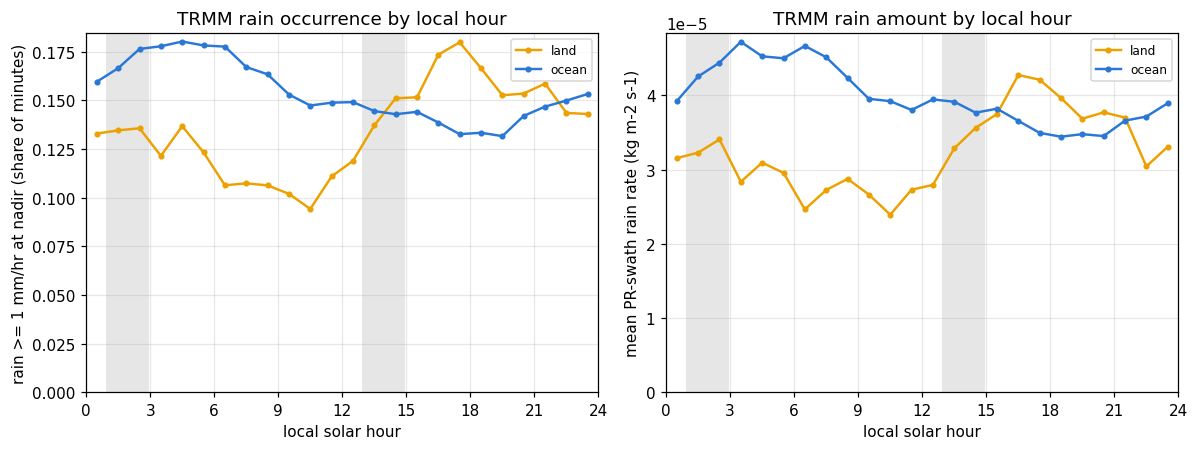

,n,window_share_of_hours,rain_amount_outside_windows,radar_rain_in_windows,radar_rain_other_hours,nadir_rain_in_windows,nadir_rain_other_hours,peak_hour_rain_amount
surface,,,,,,,,
all,"352,800",16.7%,82.8%,41.9%,41.5%,15.3%,14.8%,3
land,"93,732",16.7%,82.7%,33.3%,32.8%,14.0%,13.4%,16
ocean,"259,068",16.7%,82.9%,45.0%,44.7%,15.8%,15.4%,3



**Takeaway.** EarthCARE's windows cover 16.7% of local hours and hold
17.2% of TRMM's rain amount (land 17.3%,
ocean 17.1%): the two sampling times neither over- nor under-sample
rain overall, and 82.8% of the day's rain falls between them. Rain amount
peaks at 16:00 over land (afternoon convection) and at
03:00 over ocean (the early-morning oceanic maximum), on either side
of the windows; both match the observed diurnal cycle, a check that G5NR's daily cycle and the
local-time column are right.


In [5]:
dh = read("e12_diurnal_hourly")
ds = read("e12_diurnal_summary")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, col, lab in ((axes[0], "nadir_rain", "rain >= 1 mm/hr at nadir (share of minutes)"),
                     (axes[1], "rain_amount", "mean PR-swath rain rate (kg m-2 s-1)")):
    shade_windows(ax)
    for surf, c in (("land", "#eda100"), ("ocean", "#2a78d6")):
        g = dh[dh.surface == surf]
        ax.plot(g["hour"] + 0.5, g[col], "-o", ms=3, lw=1.6, color=c, label=surf)
    ax.set(xlabel="local solar hour", ylabel=lab, xlim=(0, 24), xticks=range(0, 25, 3), ylim=(0, None))
    ax.legend(fontsize=8)
axes[0].set_title("TRMM rain occurrence by local hour")
axes[1].set_title("TRMM rain amount by local hour")
plt.tight_layout()
plt.show()
display(ds.set_index("surface").style.format(
    {"n": "{:,}", **{c: "{:.1%}" for c in ds.columns if c not in ("surface", "n", "peak_hour_rain_amount")}}))

a, land, ocean = (ds[ds.surface == s].iloc[0] for s in ("all", "land", "ocean"))
display(Markdown(f'''
**Takeaway.** EarthCARE's windows cover {a.window_share_of_hours:.1%} of local hours and hold
{1 - a.rain_amount_outside_windows:.1%} of TRMM's rain amount (land {1 - land.rain_amount_outside_windows:.1%},
ocean {1 - ocean.rain_amount_outside_windows:.1%}): the two sampling times neither over- nor under-sample
rain overall, and {a.rain_amount_outside_windows:.1%} of the day's rain falls between them. Rain amount
peaks at {int(land.peak_hour_rain_amount):02d}:00 over land (afternoon convection) and at
{int(ocean.peak_hour_rain_amount):02d}:00 over ocean (the early-morning oceanic maximum), on either side
of the windows; both match the observed diurnal cycle, a check that G5NR's daily cycle and the
local-time column are right.
'''))

## 5. Fig. 7 and summary

Fig. 7 of the paper, drawn by `baselines/compare_missions.py` from the same result files.

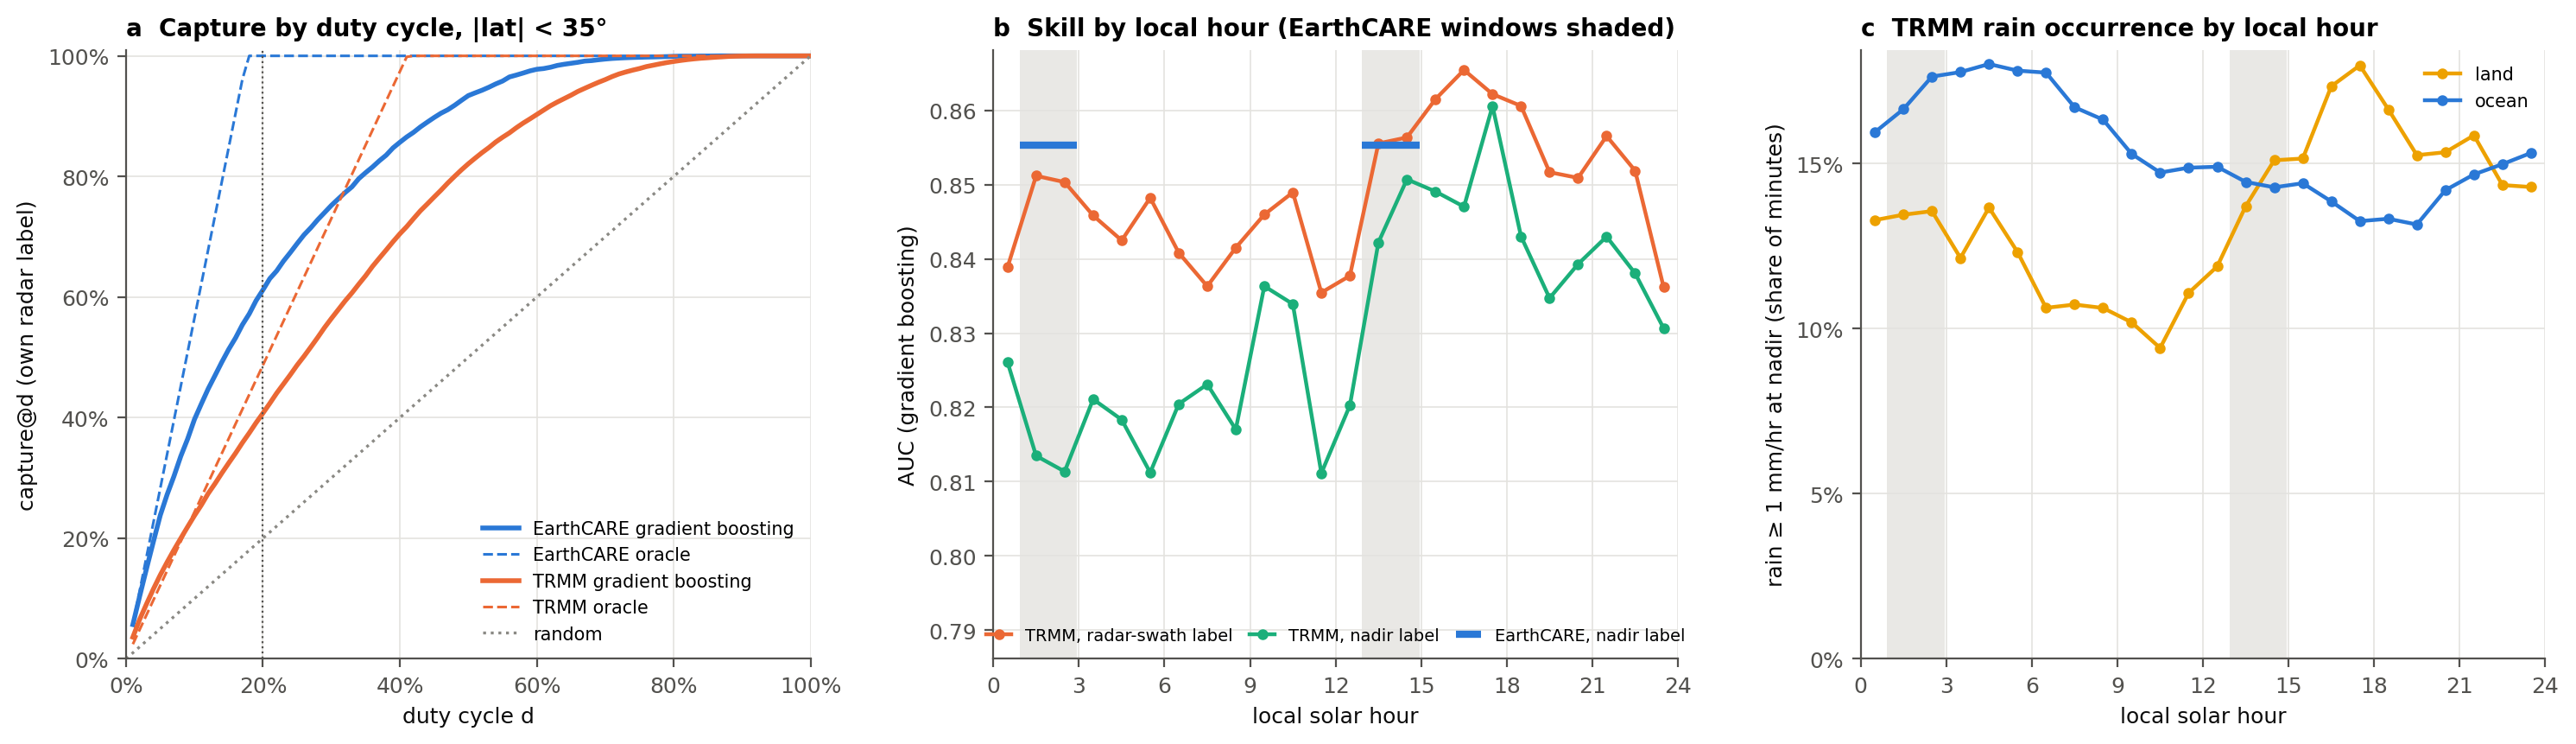

,value
quantity,
decisions in the shared band,"EarthCARE 138,424, TRMM 352,800"
"base rate, own radar label","EarthCARE 17.7%, TRMM 41.1%"
P6 AUC,"EarthCARE 0.855, TRMM 0.849"
P6 capture@20% (oracle),"EarthCARE 61.2% (100%), TRMM 40.7% (48.7%)"
"transfer loss EarthCARE -> TRMM, P6, nadir label",1.2 points
"largest transfer loss, any setting",2.5 points
TRMM capture@20% in vs. outside EarthCARE windows (P6),"43.9% vs. 40.1%, gap +3.8 [+0.8, +6.8]"
rain amount inside EarthCARE windows,17.2% of the day's (windows = 16.7% of hours)


In [6]:
display(Image(filename=str(FIG / "fig7_mission_comparison.png")))

e, t = (comp[(comp.mission == n) & (comp.policy == P6)].iloc[0] for n in ("EarthCARE", "TRMM"))
summary = pd.DataFrame([
    ("decisions in the shared band", f"EarthCARE {meta['data']['EarthCARE']['rows_in_band']:,}, TRMM {meta['data']['TRMM']['rows_in_band']:,}"),
    ("base rate, own radar label", f"EarthCARE {e.base_rate:.1%}, TRMM {t.base_rate:.1%}"),
    ("P6 AUC", f"EarthCARE {e.auc:.3f}, TRMM {t.auc:.3f}"),
    ("P6 capture@20% (oracle)", f"EarthCARE {e['capture@20%']:.1%} ({e['oracle_capture@20%']:.0%}), TRMM {t['capture@20%']:.1%} ({t['oracle_capture@20%']:.1%})"),
    ("transfer loss EarthCARE -> TRMM, P6, nadir label", f"{ec_tr.loc[P6, 'capture_loss_points@20%']:.1f} points"),
    ("largest transfer loss, any setting", f"{worst['capture_loss_points@20%']:.1f} points"),
    ("TRMM capture@20% in vs. outside EarthCARE windows (P6)", f"{g6.capture_in_windows:.1%} vs. {g6.capture_other_hours:.1%}, gap {g6.gap_points:+.1f} [{g6.gap_ci_low:+.1f}, {g6.gap_ci_high:+.1f}]"),
    ("rain amount inside EarthCARE windows", f"{1 - a.rain_amount_outside_windows:.1%} of the day's (windows = {a.window_share_of_hours:.1%} of hours)"),
], columns=["quantity", "value"]).set_index("quantity")
display(summary)